In [1]:
!pip install pandas


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
#Step1 : Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
#Step 2. Define dataset paths and load CSV files
# Load original datasets
orders = pd.read_csv("original\orders.csv")
customers = pd.read_csv("original\customers.csv")
products = pd.read_csv("original\products.csv")

# Preserve original datasets
orders_original = orders.copy(deep=True)
customers_original = customers.copy(deep=True)
products_original = products.copy(deep=True)

# Store datasets for inspection
datasets = {
    "Orders": orders,
    "Customers": customers,
    "Products": products
}

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
#Step 3. Dataset dimensions and structure
for name, df in datasets.items():

    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")

    print("Number of Rows:", df.shape[0])
    print("Number of Columns:", df.shape[1])

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nDataset Information:")
    df.info()


DATASET: ORDERS
Number of Rows: 244
Number of Columns: 8

Column Names:
['order_id', 'order_date', 'customer_id', 'product_id', 'quantity', 'unit_price', 'currency', 'status']

Data Types:
order_id       object
order_date     object
customer_id    object
product_id     object
quantity        int64
unit_price      int64
currency       object
status         object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   order_id     244 non-null    object
 1   order_date   244 non-null    object
 2   customer_id  242 non-null    object
 3   product_id   244 non-null    object
 4   quantity     244 non-null    int64 
 5   unit_price   244 non-null    int64 
 6   currency     244 non-null    object
 7   status       244 non-null    object
dtypes: int64(2), object(6)
memory usage: 15.4+ KB

DATASET: CUSTOMERS
Number of Row

In [4]:
#Step 4. First five and last five records
for name, df in datasets.items():

    print(f"\n{'='*60}")
    print(f"{name.upper()} - FIRST FIVE RECORDS")
    print(f"{'='*60}")

    display(df.head())

    print(f"\n{name.upper()} - LAST FIVE RECORDS")

    display(df.tail())


ORDERS - FIRST FIVE RECORDS


,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status
0,O0211,2026-09-12,C071,P002,1,7500,INR,completed
1,O0195,2026-09-03,C019,P005,3,900,INR,completed
2,O0051,2026-08-19,NaN,P007,3,1600,INR,completed
3,O0214,2026-09-03,C040,P003,1,6500,INR,completed
4,O0089,2026-08-07,C005,P006,1,4400,INR,completed



ORDERS - LAST FIVE RECORDS


,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status
239,O0107,2026-08-08,C073,P011,1,8200,INR,completed
240,O0147,2026-09-18,C048,P008,1,2500,INR,completed
241,O0097,2026-08-15,C067,P006,2,2200,INR,completed
242,O0065,2026-08-06,C080,P012,1,15000,INR,completed
243,O0152,2026-09-10,C047,P003,1,6500,INR,completed



CUSTOMERS - FIRST FIVE RECORDS


,customer_id,customer_name,region
0,C001,Customer 001,South
1,C002,Customer 002,West
2,C003,Customer 003,North
3,C004,Customer 004,South
4,C005,Customer 005,West


... (2 outputs left out)


PRODUCTS - FIRST FIVE RECORDS


,product_id,product_name,category
0,P001,Laptop 14,Computers
1,P002,USB-C Dock,Accessories
2,P003,SSD 1TB,Storage
3,P004,24in Monitor,Displays
4,P005,Wireless Mouse,Accessories



PRODUCTS - LAST FIVE RECORDS


,product_id,product_name,category
7,P008,Webcam,Audio
8,P009,Router,Networking
9,P010,Laptop 16,Computers
10,P011,HDD 4TB,Storage
11,P012,Printer,Printers


In [5]:
#Step 5. Statistical summary
for name, df in datasets.items():

    print(f"\n{'='*60}")
    print(f"STATISTICAL SUMMARY: {name.upper()}")
    print(f"{'='*60}")

    display(df.describe(include='all').T)


STATISTICAL SUMMARY: ORDERS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,244,240,O0089,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,244,58,2026-08-08,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,242,79,C049,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,244,14,P005,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,244.0,NaN,NaN,NaN,1.229508,0.509771,-1.0,1.0,1.0,1.0,3.0
unit_price,244.0,NaN,NaN,NaN,10813.934426,17453.636717,0.0,2050.0,5500.0,8200.0,72000.0
currency,244,3,INR,242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,244,5,completed,211,NaN,NaN,NaN,NaN,NaN,NaN,NaN



STATISTICAL SUMMARY: CUSTOMERS


,count,unique,top,freq
customer_id,80,80,C001,1
customer_name,80,80,Customer 001,1
region,80,3,South,27



STATISTICAL SUMMARY: PRODUCTS


,count,unique,top,freq
product_id,12,12,P001,1
product_name,12,12,Laptop 14,1
category,12,7,Accessories,3


In [7]:
#Step 6. Missing values analysis
for name, df in datasets.items():

    print(f"\n{'='*60}")
    print(f"MISSING VALUE ANALYSIS: {name.upper()}")
    print(f"{'='*60}")

    missing = pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": (df.isnull().mean() * 100).round(2)
    })

    display(missing[missing["Missing_Count"] > 0]
            .sort_values("Missing_Count", ascending=False))

    if df.isnull().sum().sum() == 0:
        print("No missing values found.")


MISSING VALUE ANALYSIS: ORDERS


,Missing_Count,Missing_Percentage
customer_id,2,0.82



MISSING VALUE ANALYSIS: CUSTOMERS


,Missing_Count,Missing_Percentage


No missing values found.

MISSING VALUE ANALYSIS: PRODUCTS


,Missing_Count,Missing_Percentage


No missing values found.


In [9]:
#Step 7. Duplicate record analysis
for name, df in datasets.items():

    print(f"\n{'='*60}")
    print(f"DUPLICATE ANALYSIS: {name.upper()}")
    print(f"{'='*60}")

    exact_duplicates = df.duplicated().sum()

    print("Exact Duplicate Rows:", exact_duplicates)

    if "order_id" in df.columns:

        duplicate_ids = df[
            df.duplicated(subset=["order_id"], keep=False)
        ].sort_values("order_id")

        print("Records with Repeated Order IDs:", len(duplicate_ids))

        if not duplicate_ids.empty:
            display(duplicate_ids)


DUPLICATE ANALYSIS: ORDERS
Exact Duplicate Rows: 3
Records with Repeated Order IDs: 8


,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status
60,O0008,2026-08-25,C024,P005,1,900,INR,cancelled
137,O0008,2026-08-25,C024,P005,1,900,INR,cancelled
48,O0030,2026-08-19,C044,P011,2,8200,INR,completed
80,O0030,2026-08-19,C044,P011,2,8200,INR,completed
73,O0081,2026-08-12,C066,P009,2,4500,INR,completed
172,O0081,2026-08-12,C066,P009,2,4500,INR,completed
4,O0089,2026-08-07,C005,P006,1,4400,INR,completed
214,O0089,2026-08-07,C005,P006,1,2200,INR,completed



DUPLICATE ANALYSIS: CUSTOMERS
Exact Duplicate Rows: 0

DUPLICATE ANALYSIS: PRODUCTS
Exact Duplicate Rows: 0


In [10]:
#Step 8. Unique values and categorical distributions
for name, df in datasets.items():

    print(f"\n{'='*60}")
    print(f"UNIQUE VALUE ANALYSIS: {name.upper()}")
    print(f"{'='*60}")

    for col in df.columns:

        print(f"\nColumn: {col}")
        print("Unique Values:", df[col].nunique(dropna=True))

        if df[col].dtype == "object":
            display(df[col].value_counts(dropna=False))


UNIQUE VALUE ANALYSIS: ORDERS

Column: order_id
Unique Values: 240


order_id
O0089    2
O0081    2
O0008    2
O0030    2
O0214    1
        ..
O0107    1
O0147    1
O0097    1
O0065    1
O0152    1
Name: count, Length: 240, dtype: int64


Column: order_date
Unique Values: 58


order_date
2026-08-08    11
2026-08-21     9
2026-08-06     9
2026-08-19     8
2026-08-22     8
2026-09-19     7
2026-08-27     7
2026-08-02     7
2026-09-23     7
2026-08-23     7
2026-08-13     6
2026-09-11     6
2026-09-15     6
2026-08-09     6
2026-08-07     6
2026-09-03     6
2026-08-01     6
2026-09-10     5
2026-08-25     5
2026-08-05     5
2026-09-17     5
2026-09-20     5
2026-08-12     4
2026-08-04     4
2026-09-16     4
2026-08-17     4
2026-08-10     4
2026-09-09     4
2026-09-18     4
2026-09-21     4
2026-09-14     4
2026-08-28     4
2026-09-25     4
2026-09-12     3
2026-08-16     3
2026-08-15     3
2026-09-02     3
2026-08-26     3
2026-09-24     3
2026-09-22     3
2026-08-20     3
2026-08-14     3
2026-09-01     3
2026-09-28     3
2026-09-04     2
2026-09-07     2
2026-08-03     2
2026-09-06     2
2026-09-27     2
2026-09-08     2
2026-08-24     1
2026-08-11     1
not-a-date     1
2026-09-26     1
2026/08/13     1
2026-08-18     1
2026-09-31     1
2026/08/19     1
Nam


Column: customer_id
Unique Values: 79


customer_id
C044    7
C049    7
C010    7
C070    7
C061    6
C067    6
C005    5
C071    5
C047    5
C073    5
C066    5
C004    5
C019    5
C076    5
C027    4
C040    4
C075    4
C022    4
C029    4
C053    4
C017    4
C063    4
C006    4
C058    4
C002    4
C024    4
C065    4
C020    4
C048    4
C057    4
C018    3
C016    3
C014    3
C068    3
C033    3
C034    3
C009    3
C078    3
C037    3
C003    3
C023    3
C077    3
C054    3
C028    2
C021    2
C011    2
NaN     2
C079    2
C031    2
C030    2
C035    2
C043    2
C062    2
C060    2
C036    2
C007    2
C025    2
C039    2
C041    2
C045    2
C056    2
C008    2
C074    2
C059    2
C013    2
C064    2
C015    2
C072    1
C998    1
C999    1
C001    1
C038    1
C050    1
C052    1
C055    1
C042    1
C051    1
C026    1
C069    1
C080    1
Name: count, dtype: int64

... (14 outputs left out)


Column: product_name
Unique Values: 12


product_name
Laptop 14         1
USB-C Dock        1
SSD 1TB           1
24in Monitor      1
Wireless Mouse    1
Headset           1
Keyboard          1
Webcam            1
Router            1
Laptop 16         1
HDD 4TB           1
Printer           1
Name: count, dtype: int64


Column: category
Unique Values: 7


category
Accessories    3
Computers      2
Storage        2
Audio          2
Displays       1
Networking     1
Printers       1
Name: count, dtype: int64

In [11]:
#Step 9. Generate initial data-health summary
health_report = []

for name, df in datasets.items():

    health_report.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing_Values": df.isnull().sum().sum(),
        "Exact_Duplicates": df.duplicated().sum(),
        "Complete_Rows_Percentage": round(
            (1 - df.isnull().any(axis=1).mean()) * 100, 2
        )
    })

health_report_df = pd.DataFrame(health_report)

display(health_report_df)

,Dataset,Rows,Columns,Missing_Values,Exact_Duplicates,Complete_Rows_Percentage
0,Orders,244,8,2,3,99.18
1,Customers,80,3,0,0,100.00
2,Products,12,3,0,0,100.00


In [12]:
#Detailed data-quality investigation
#Step 10. Inspect all repeated order IDs
# Identify every repeated order ID
duplicate_order_ids = orders[
    orders.duplicated(subset=["order_id"], keep=False)
].sort_values("order_id")

display(duplicate_order_ids)

# Count occurrences of each repeated order ID
duplicate_summary = (
    duplicate_order_ids
    .groupby("order_id")
    .size()
    .reset_index(name="record_count")
)

display(duplicate_summary)

,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status
60,O0008,2026-08-25,C024,P005,1,900,INR,cancelled
137,O0008,2026-08-25,C024,P005,1,900,INR,cancelled
48,O0030,2026-08-19,C044,P011,2,8200,INR,completed
80,O0030,2026-08-19,C044,P011,2,8200,INR,completed
73,O0081,2026-08-12,C066,P009,2,4500,INR,completed
172,O0081,2026-08-12,C066,P009,2,4500,INR,completed
4,O0089,2026-08-07,C005,P006,1,4400,INR,completed
214,O0089,2026-08-07,C005,P006,1,2200,INR,completed


,order_id,record_count
0,O0008,2
1,O0030,2
2,O0081,2
3,O0089,2


In [13]:
#Step 11. Investigate missing and invalid foreign keys
# Identify missing customer IDs
missing_customer_records = orders[
    orders["customer_id"].isna()
]

# Identify customer IDs not found in customers table
invalid_customer_records = orders[
    orders["customer_id"].notna() &
    ~orders["customer_id"].isin(customers["customer_id"])
]

# Identify product IDs not found in products table
invalid_product_records = orders[
    ~orders["product_id"].isin(products["product_id"])
]

print("Missing Customer IDs:", len(missing_customer_records))
print("Unmatched Customer IDs:", len(invalid_customer_records))
print("Unmatched Product IDs:", len(invalid_product_records))

print("\nMissing Customer Records:")
display(missing_customer_records)

print("\nUnmatched Customer Records:")
display(invalid_customer_records)

print("\nUnmatched Product Records:")
display(invalid_product_records)

Missing Customer IDs: 2
Unmatched Customer IDs: 2
Unmatched Product IDs: 2

Missing Customer Records:


,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status
2,O0051,2026-08-19,NaN,P007,3,1600,INR,completed
54,O0052,2026-08-28,NaN,P012,1,15000,INR,cancelled



Unmatched Customer Records:


,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status
79,O0042,2026-08-06,C999,P003,1,6500,INR,completed
91,O0043,2026-08-06,C998,P004,1,13000,INR,completed



Unmatched Product Records:


,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status
121,O0045,2026-08-23,C002,P998,1,13000,INR,completed
210,O0044,2026-08-21,C065,P999,1,2200,INR,completed


In [14]:
#Step 12. Investigate invalid quantities and prices
# Invalid quantities
invalid_quantity = orders[
    orders["quantity"] <= 0
]

# Invalid prices
invalid_price = orders[
    orders["unit_price"] <= 0
]

print("Non-positive quantities:", len(invalid_quantity))
print("Non-positive unit prices:", len(invalid_price))

print("\nInvalid Quantity Records:")
display(invalid_quantity)

print("\nInvalid Price Records:")
display(invalid_price)

Non-positive quantities: 2
Non-positive unit prices: 1

Invalid Quantity Records:


,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status
77,O0059,2026-08-02,C033,P005,0,900,INR,completed
123,O0053,2026-08-06,C038,P003,-1,6500,INR,completed



Invalid Price Records:


,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status
11,O0054,2026-08-17,C044,P011,2,0,INR,completed


In [16]:
#Step 13. Investigate date formats
# Parse dates without modifying original column
parsed_dates = pd.to_datetime(
    orders["order_date"],
    format="mixed",
    errors="coerce"
)

# Identify dates that cannot be parsed
invalid_date_records = orders[
    parsed_dates.isna()
]

print("Total invalid/unparsed dates:", len(invalid_date_records))

display(invalid_date_records[
    ["order_id", "order_date", "status"]
])

Total invalid/unparsed dates: 2


,order_id,order_date,status
67,O0037,not-a-date,completed
185,O0036,2026-09-31,completed


In [17]:
#successfully parsed data
print("Earliest valid date:", parsed_dates.min())
print("Latest valid date:", parsed_dates.max())

print("\nDate parsing results:")
display(pd.DataFrame({
    "Original_Date": orders["order_date"],
    "Parsed_Date": parsed_dates
}).head(15))

Earliest valid date: 2026-08-01 00:00:00
Latest valid date: 2026-09-28 00:00:00

Date parsing results:


,Original_Date,Parsed_Date
0,2026-09-12,2026-09-12
1,2026-09-03,2026-09-03
2,2026-08-19,2026-08-19
3,2026-09-03,2026-09-03
4,2026-08-07,2026-08-07
5,2026-08-01,2026-08-01
6,2026-08-01,2026-08-01
7,2026-08-06,2026-08-06
8,2026-09-17,2026-09-17
9,2026-09-19,2026-09-19


In [18]:
#Step 14. Investigate statuses and currencies
print("STATUS DISTRIBUTION")
display(
    orders["status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="record_count")
)

print("\nCURRENCY DISTRIBUTION")
display(
    orders["currency"]
    .value_counts(dropna=False)
    .rename_axis("currency")
    .reset_index(name="record_count")
)

STATUS DISTRIBUTION


,status,record_count
0,completed,211
1,refunded,16
2,cancelled,15
3,Completed,1
4,COMPLETE,1



CURRENCY DISTRIBUTION


,currency,record_count
0,INR,242
1,EUR,1
2,USD,1


In [19]:
#Implement cleaning with an audit trail
#Step 15. Create a working copy and identify exact duplicates
# Create working copy
working_orders = orders_original.copy(deep=True)

# Preserve original row index for audit purposes
working_orders["source_row_index"] = working_orders.index

# Identify exact duplicate rows
exact_duplicate_mask = working_orders.duplicated(
    subset=orders_original.columns.tolist(),
    keep="first"
)

# Store duplicate copies for audit
duplicate_records = working_orders[exact_duplicate_mask].copy()

duplicate_records["rejection_reason"] = "Exact duplicate record"
duplicate_records["cleaning_decision"] = "Removed duplicate copy"

# Retain first occurrence
deduplicated_orders = working_orders[~exact_duplicate_mask].copy()

print("Original records:", len(working_orders))
print("Exact duplicate copies:", len(duplicate_records))
print("Records after deduplication:", len(deduplicated_orders))

Original records: 244
Exact duplicate copies: 3
Records after deduplication: 241


In [20]:
#Step 16. Identify conflicting order IDs
# Identify order IDs appearing more than once after exact deduplication
conflicting_ids = deduplicated_orders[
    deduplicated_orders.duplicated(
        subset=["order_id"],
        keep=False
    )
]["order_id"].unique()

conflicting_records = deduplicated_orders[
    deduplicated_orders["order_id"].isin(conflicting_ids)
].copy()

print("Conflicting order IDs:", conflicting_ids)

display(
    conflicting_records.sort_values("order_id")
)

Conflicting order IDs: ['O0089']


,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status,source_row_index
4,O0089,2026-08-07,C005,P006,1,4400,INR,completed,4
214,O0089,2026-08-07,C005,P006,1,2200,INR,completed,214


In [21]:
#Step 17. Apply validation rules
# Work on a separate copy
validated_orders = deduplicated_orders.copy()

# Normalize status and currency
validated_orders["status_normalized"] = (
    validated_orders["status"].astype("string").str.strip().str.lower()
)

validated_orders["currency_normalized"] = (
    validated_orders["currency"].astype("string").str.strip().str.upper()
)

# Parse dates
validated_orders["parsed_date"] = pd.to_datetime(
    validated_orders["order_date"],
    format="mixed",
    errors="coerce"
)

# Referential integrity checks
missing_customer = validated_orders["customer_id"].isna()

unmatched_customer = (
    validated_orders["customer_id"].notna() &
    ~validated_orders["customer_id"].isin(customers_original["customer_id"])
)

unmatched_product = ~validated_orders["product_id"].isin(
    products_original["product_id"]
)

# Business validation
invalid_quantity = validated_orders["quantity"] <= 0
invalid_price = validated_orders["unit_price"] <= 0

invalid_date = validated_orders["parsed_date"].isna()

conflicting_order = validated_orders["order_id"].isin(conflicting_ids)

unsupported_status = ~validated_orders["status_normalized"].isin(
    ["completed", "cancelled", "refunded"]
)

unsupported_currency = ~validated_orders["currency_normalized"].isin(
    ["INR", "USD"]
)

# Create validation flags
validation_flags = pd.DataFrame({
    "conflicting_order_id": conflicting_order,
    "missing_customer_id": missing_customer,
    "unmatched_customer_id": unmatched_customer,
    "unmatched_product_id": unmatched_product,
    "invalid_quantity": invalid_quantity,
    "invalid_price": invalid_price,
    "invalid_date": invalid_date,
    "unsupported_status": unsupported_status,
    "unsupported_currency": unsupported_currency
}, index=validated_orders.index)

display(validation_flags.sum().to_frame("Affected_Records"))

,Affected_Records
conflicting_order_id,2
missing_customer_id,2
unmatched_customer_id,2
unmatched_product_id,2
invalid_quantity,2
invalid_price,1
invalid_date,2
unsupported_status,1
unsupported_currency,1


In [22]:
#Step 18. Generate record-level rejection reasons
# Convert validation flags into readable reasons
rejection_reasons = []

for idx, row in validation_flags.iterrows():

    reasons = [
        column for column, value in row.items() if value
    ]

    # Exclude cancelled and refunded orders from eligible revenue
    status = validated_orders.loc[idx, "status_normalized"]

    if status == "cancelled":
        reasons.append("Cancelled order")

    elif status == "refunded":
        reasons.append("Refunded order")

    rejection_reasons.append("; ".join(reasons))

validated_orders["rejection_reason"] = rejection_reasons

# Determine eligibility
validated_orders["is_eligible"] = (
    validated_orders["rejection_reason"] == ""
)

# Separate eligible and rejected records
clean_orders = validated_orders[
    validated_orders["is_eligible"]
].copy()

rejected_orders = validated_orders[
    ~validated_orders["is_eligible"]
].copy()

print("Eligible records:", len(clean_orders))
print("Rejected/excluded records:", len(rejected_orders))

display(
    rejected_orders[
        ["source_row_index", "order_id", "rejection_reason"]
    ]
)

Eligible records: 197
Rejected/excluded records: 44


,source_row_index,order_id,rejection_reason
2,2,O0051,missing_customer_id
4,4,O0089,conflicting_order_id
5,5,O0056,unsupported_status
11,11,O0054,invalid_price
13,13,O0106,Cancelled order
32,32,O0203,Refunded order
35,35,O0160,Cancelled order
46,46,O0102,Cancelled order
54,54,O0052,missing_customer_id; Cancelled order
60,60,O0008,Cancelled order


In [23]:
#Step 19. Calculate trusted revenue in INR
# Exchange rates specified by the challenge
exchange_rates = {
    "INR": 1,
    "USD": 85
}

# Map exchange rates
clean_orders["exchange_rate"] = (
    clean_orders["currency_normalized"].map(exchange_rates)
)

# Calculate transaction revenue
clean_orders["revenue_inr"] = (
    clean_orders["quantity"] *
    clean_orders["unit_price"] *
    clean_orders["exchange_rate"]
)

# Change status to normalized value in processed output
clean_orders["status"] = clean_orders["status_normalized"]

print("Trusted completed revenue records:")
display(clean_orders.head())

print(
    "Total trusted revenue (INR):",
    clean_orders["revenue_inr"].sum()
)

Trusted completed revenue records:


,order_id,order_date,customer_id,product_id,quantity,unit_price,currency,status,source_row_index,status_normalized,currency_normalized,parsed_date,rejection_reason,is_eligible,exchange_rate,revenue_inr
0,O0211,2026-09-12,C071,P002,1,7500,INR,completed,0,completed,INR,2026-09-12,,True,1,7500
1,O0195,2026-09-03,C019,P005,3,900,INR,completed,1,completed,INR,2026-09-03,,True,1,2700
3,O0214,2026-09-03,C040,P003,1,6500,INR,completed,3,completed,INR,2026-09-03,,True,1,6500
6,O0083,2026-08-01,C016,P012,1,15000,INR,completed,6,completed,INR,2026-08-01,,True,1,15000
7,O0096,2026-08-06,C071,P005,1,900,INR,completed,7,completed,INR,2026-08-06,,True,1,900


Total trusted revenue (INR): 2946400


In [28]:
#Step 20. Generate cleaning audit report
# Audit for rejected and excluded records
audit_rejected = rejected_orders[
    ["source_row_index", "order_id", "rejection_reason"]
].copy()

audit_rejected["cleaning_decision"] = "Excluded from trusted revenue"

# Audit for exact duplicate copies
audit_duplicates = duplicate_records[
    ["source_row_index", "order_id", "rejection_reason"]
].copy()

audit_duplicates["cleaning_decision"] = (
    "Removed duplicate copy; original retained"
)

audit = pd.concat(
    [audit_rejected, audit_duplicates],
    ignore_index=True
)

display(audit.sort_values("order_id"))

,source_row_index,order_id,rejection_reason,cleaning_decision
13,76,O0003,Refunded order,Excluded from trusted revenue
45,137,O0008,Exact duplicate record,Removed duplicate copy; original retained
9,60,O0008,Cancelled order,Excluded from trusted revenue
33,155,O0029,Refunded order,Excluded from trusted revenue
44,80,O0030,Exact duplicate record,Removed duplicate copy; original retained
36,185,O0036,invalid_date,Excluded from trusted revenue
10,67,O0037,invalid_date,Excluded from trusted revenue
15,79,O0042,unmatched_customer_id,Excluded from trusted revenue
17,91,O0043,unmatched_customer_id,Excluded from trusted revenue
39,210,O0044,unmatched_product_id,Excluded from trusted revenue


In [29]:
#Step 21. Export processed datasets
os.makedirs("output", exist_ok=True)

clean_orders.to_csv(
    "output/clean_orders.csv",
    index=False
)

rejected_orders.to_csv(
    "output/rejected_orders.csv",
    index=False
)

duplicate_records.to_csv(
    "output/duplicate_records.csv",
    index=False
)

audit.to_csv(
    "output/data_quality_audit.csv",
    index=False
)

print("Processed datasets and audit reports exported successfully.")

Processed datasets and audit reports exported successfully.


In [30]:
#Validation checkpoint
# Check 1: No duplicate order IDs in trusted dataset
print(
    "Duplicate IDs in clean dataset:",
    clean_orders["order_id"].duplicated().sum()
)

# Check 2: No invalid quantities
print(
    "Invalid quantities:",
    (clean_orders["quantity"] <= 0).sum()
)

# Check 3: No invalid prices
print(
    "Invalid prices:",
    (clean_orders["unit_price"] <= 0).sum()
)

# Check 4: Only completed transactions
print(
    "Statuses in clean dataset:",
    clean_orders["status"].value_counts()
)

# Check 5: Supported currencies only
print(
    "Currencies in clean dataset:",
    clean_orders["currency_normalized"].value_counts()
)

# Check 6: No missing customer/product keys
print(
    "Missing customer IDs:",
    clean_orders["customer_id"].isna().sum()
)

print(
    "Unmatched product IDs:",
    (~clean_orders["product_id"].isin(products_original["product_id"])).sum()
)

# Check 7: Revenue reconciliation
expected_revenue = (
    clean_orders["quantity"] *
    clean_orders["unit_price"] *
    clean_orders["exchange_rate"]
).sum()

print("Calculated revenue:", expected_revenue)
print("Stored revenue:", clean_orders["revenue_inr"].sum())

assert expected_revenue == clean_orders["revenue_inr"].sum()
assert clean_orders["order_id"].is_unique

Duplicate IDs in clean dataset: 0
Invalid quantities: 0
Invalid prices: 0
Statuses in clean dataset: status
completed    197
Name: count, dtype: Int64
Currencies in clean dataset: currency_normalized
INR    196
USD      1
Name: count, dtype: Int64
Missing customer IDs: 0
Unmatched product IDs: 0
Calculated revenue: 2946400
Stored revenue: 2946400


In [31]:
#Step 22. Prepare the trusted dataset for SQL
import sqlite3

# Create a SQL-ready copy
sql_ready = clean_orders.copy()

# Standardize date format
sql_ready["order_date_clean"] = (
    pd.to_datetime(sql_ready["parsed_date"])
    .dt.strftime("%Y-%m-%d")
)

# Create SQLite connection
conn = sqlite3.connect(":memory:")

# Load trusted dataset
sql_ready.to_sql(
    "clean_orders",
    conn,
    if_exists="replace",
    index=False
)

print("Trusted dataset successfully loaded into SQLite.")

Trusted dataset successfully loaded into SQLite.


In [32]:
#Step 23. Execute monthly revenue SQL
monthly_revenue_query = """
WITH monthly_sales AS (

    SELECT
        strftime('%Y-%m', order_date_clean) AS sales_month,

        MIN(order_date_clean) AS first_transaction_date,
        MAX(order_date_clean) AS last_transaction_date,

        COUNT(DISTINCT order_id) AS total_transactions,

        COUNT(DISTINCT order_date_clean) AS active_sales_days,

        SUM(quantity) AS total_units_sold,

        SUM(revenue_inr) AS total_revenue,

        AVG(revenue_inr) AS average_transaction_value

    FROM clean_orders

    WHERE status = 'completed'

    GROUP BY strftime('%Y-%m', order_date_clean)
),

revenue_comparison AS (

    SELECT
        *,

        LAG(total_revenue) OVER (
            ORDER BY sales_month
        ) AS previous_month_revenue

    FROM monthly_sales
)

SELECT
    sales_month,
    first_transaction_date,
    last_transaction_date,
    active_sales_days,
    total_transactions,
    total_units_sold,
    total_revenue,
    ROUND(average_transaction_value, 2)
        AS average_transaction_value,

    ROUND(
        total_revenue - previous_month_revenue, 2
    ) AS revenue_change,

    ROUND(
        100.0 * (
            total_revenue - previous_month_revenue
        ) / NULLIF(previous_month_revenue, 0),
        2
    ) AS revenue_growth_percentage

FROM revenue_comparison

ORDER BY sales_month;
"""

monthly_sql_results = pd.read_sql_query(
    monthly_revenue_query,
    conn
)

display(monthly_sql_results)

,sales_month,first_transaction_date,last_transaction_date,active_sales_days,total_transactions,total_units_sold,total_revenue,average_transaction_value,revenue_change,revenue_growth_percentage
0,2026-08,2026-08-01,2026-08-28,28,113,135,1809000,16008.85,NaN,NaN
1,2026-09,2026-09-01,2026-09-28,26,84,110,1137400,13540.48,-671600.0,-37.13


In [33]:
#Step 24. Independently validate using Pandas
# Create reporting month
clean_orders["reporting_month"] = (
    clean_orders["parsed_date"].dt.to_period("M").astype(str)
)

# Independent Pandas calculation
monthly_pandas = (
    clean_orders.groupby("reporting_month")
    .agg(
        total_transactions=("order_id", "nunique"),
        total_units_sold=("quantity", "sum"),
        total_revenue=("revenue_inr", "sum"),
        average_transaction_value=("revenue_inr", "mean"),
        first_transaction_date=("parsed_date", "min"),
        last_transaction_date=("parsed_date", "max")
    )
    .reset_index()
)

display(monthly_pandas)

,reporting_month,total_transactions,total_units_sold,total_revenue,average_transaction_value,first_transaction_date,last_transaction_date
0,2026-08,113,135,1809000,16008.849558,2026-08-01,2026-08-28
1,2026-09,84,110,1137400,13540.476190,2026-09-01,2026-09-28


In [35]:
#DEBUG: inspect the merged column names
print(comparison.columns.tolist())

['sales_month', 'first_transaction_date_sql', 'last_transaction_date_sql', 'active_sales_days', 'total_transactions_sql', 'total_units_sold_sql', 'total_revenue_sql', 'average_transaction_value_sql', 'revenue_change', 'revenue_growth_percentage', 'reporting_month', 'total_transactions_pandas', 'total_units_sold_pandas', 'total_revenue_pandas', 'average_transaction_value_pandas', 'first_transaction_date_pandas', 'last_transaction_date_pandas']


In [ ]:
#Step 25. Revenue reconciliation BY Comparing SQL and Pandas results
# Compare SQL and Pandas revenue calculations
comparison["revenue_difference"] = (
    comparison["total_revenue_sql"] -
    comparison["total_revenue_pandas"]
)

display(
    comparison[[
        "sales_month",
        "total_revenue_sql",
        "total_revenue_pandas",
        "revenue_difference"
    ]]
)

# Validate revenue calculations
assert np.allclose(
    comparison["total_revenue_sql"],
    comparison["total_revenue_pandas"]
), "Revenue mismatch detected!"

print("SUCCESS: SQL and Pandas revenue calculations reconciled.")

,sales_month,total_revenue_sql,total_revenue_pandas,revenue_difference
0,2026-08,1809000,1809000,0
1,2026-09,1137400,1137400,0


SUCCESS: SQL and Pandas revenue calculations reconciled.


In [39]:
#DEBUG: Load the products table
products_sql = products_original.copy()

products_sql.to_sql(
    "products",
    conn,
    if_exists="replace",
    index=False
)

print("Products table successfully loaded into SQLite.")

Products table successfully loaded into SQLite.


In [40]:
#Verify the table
pd.read_sql_query(
    "SELECT * FROM products LIMIT 5",
    conn
)

,product_id,product_name,category
0,P001,Laptop 14,Computers
1,P002,USB-C Dock,Accessories
2,P003,SSD 1TB,Storage
3,P004,24in Monitor,Displays
4,P005,Wireless Mouse,Accessories


In [41]:
#Step 26: Identify the top 10 products by revenue
top_products_query = """
SELECT
    p.product_id,
    p.product_name,
    p.category,
    SUM(c.quantity) AS total_units_sold,
    COUNT(DISTINCT c.order_id) AS total_orders,
    ROUND(SUM(c.revenue_inr), 2) AS total_revenue,
    ROUND(
        100.0 * SUM(c.revenue_inr) /
        (SELECT SUM(revenue_inr) FROM clean_orders),
        2
    ) AS revenue_contribution_percentage
FROM clean_orders c
JOIN products p
    ON c.product_id = p.product_id
GROUP BY
    p.product_id,
    p.product_name,
    p.category
ORDER BY total_revenue DESC
LIMIT 10;
"""

top_products = pd.read_sql_query(top_products_query, conn)

display(top_products)

,product_id,product_name,category,total_units_sold,total_orders,total_revenue,revenue_contribution_percentage
0,P010,Laptop 16,Computers,15,11,1080000.0,36.65
1,P001,Laptop 14,Computers,13,10,650000.0,22.06
2,P011,HDD 4TB,Storage,29,25,237800.0,8.07
3,P012,Printer,Printers,15,11,225000.0,7.64
4,P002,USB-C Dock,Accessories,27,21,202500.0,6.87
5,P004,24in Monitor,Displays,14,11,182000.0,6.18
6,P003,SSD 1TB,Storage,21,18,136500.0,4.63
7,P009,Router,Networking,17,13,80500.0,2.73
8,P006,Headset,Audio,29,23,63800.0,2.17
9,P007,Keyboard,Accessories,22,19,35200.0,1.19


In [42]:
#Step: 27 Compare product revenue between August and September
product_month_query = """
SELECT
    p.product_id,
    p.product_name,
    p.category,

    SUM(CASE
        WHEN strftime('%m', c.order_date_clean) = '08'
        THEN c.revenue_inr ELSE 0
    END) AS august_revenue,

    SUM(CASE
        WHEN strftime('%m', c.order_date_clean) = '09'
        THEN c.revenue_inr ELSE 0
    END) AS september_revenue,

    SUM(CASE
        WHEN strftime('%m', c.order_date_clean) = '09'
        THEN c.revenue_inr ELSE 0
    END)
    -
    SUM(CASE
        WHEN strftime('%m', c.order_date_clean) = '08'
        THEN c.revenue_inr ELSE 0
    END) AS revenue_change

FROM clean_orders c
JOIN products p
    ON c.product_id = p.product_id

GROUP BY p.product_id, p.product_name, p.category
ORDER BY revenue_change ASC;
"""

product_month_comparison = pd.read_sql_query(
    product_month_query, conn
)

display(product_month_comparison)

,product_id,product_name,category,august_revenue,september_revenue,revenue_change
0,P010,Laptop 16,Computers,936000,144000,-792000
1,P004,24in Monitor,Displays,130000,52000,-78000
2,P009,Router,Networking,67000,13500,-53500
3,P011,HDD 4TB,Storage,139400,98400,-41000
4,P003,SSD 1TB,Storage,78000,58500,-19500
5,P005,Wireless Mouse,Accessories,17100,13500,-3600
6,P007,Keyboard,Accessories,17600,17600,0
7,P008,Webcam,Audio,10000,12500,2500
8,P002,USB-C Dock,Accessories,97500,105000,7500
9,P006,Headset,Audio,26400,37400,11000


In [43]:
#Step 28: Analyze new vs repeat customers
customer_analysis_query = """
WITH ranked_orders AS (
    SELECT
        order_id,
        customer_id,
        order_date_clean,
        revenue_inr,
        ROW_NUMBER() OVER (
            PARTITION BY customer_id
            ORDER BY order_date_clean, order_id
        ) AS order_number
    FROM clean_orders
),

customer_segments AS (
    SELECT
        *,
        CASE
            WHEN order_number = 1 THEN 'New'
            ELSE 'Repeat'
        END AS customer_type
    FROM ranked_orders
)

SELECT
    strftime('%Y-%m', order_date_clean) AS sales_month,
    customer_type,
    COUNT(DISTINCT customer_id) AS total_customers,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(revenue_inr), 2) AS total_revenue,
    ROUND(AVG(revenue_inr), 2) AS average_order_revenue

FROM customer_segments

GROUP BY
    strftime('%Y-%m', order_date_clean),
    customer_type

ORDER BY
    sales_month,
    customer_type;
"""

customer_analysis = pd.read_sql_query(
    customer_analysis_query, conn
)

display(customer_analysis)

,sales_month,customer_type,total_customers,total_orders,total_revenue,average_order_revenue
0,2026-08,New,64,64,580400.0,9068.75
1,2026-08,Repeat,37,49,1228600.0,25073.47
2,2026-09,New,10,10,161600.0,16160.00
3,2026-09,Repeat,44,74,975800.0,13186.49


In [44]:
#Step 29: Investigate why Laptop 16 revenue declined
laptop16_query = """
SELECT
    strftime('%Y-%m', order_date_clean) AS sales_month,
    COUNT(DISTINCT order_id) AS total_orders,
    SUM(quantity) AS units_sold,
    ROUND(SUM(revenue_inr), 2) AS total_revenue,
    ROUND(AVG(unit_price), 2) AS average_unit_price
FROM clean_orders
WHERE product_id = 'P010'
GROUP BY strftime('%Y-%m', order_date_clean)
ORDER BY sales_month;
"""

laptop16_analysis = pd.read_sql_query(
    laptop16_query, conn
)

display(laptop16_analysis)

,sales_month,total_orders,units_sold,total_revenue,average_unit_price
0,2026-08,9,13,936000.0,72000.0
1,2026-09,2,2,144000.0,72000.0


In [45]:
#Step 30: Final validation
coverage_query = """
SELECT
    strftime('%Y-%m', order_date_clean) AS sales_month,
    MIN(order_date_clean) AS first_order_date,
    MAX(order_date_clean) AS last_order_date,
    COUNT(DISTINCT order_date_clean) AS active_sales_days,
    COUNT(DISTINCT order_id) AS total_orders
FROM clean_orders
GROUP BY strftime('%Y-%m', order_date_clean)
ORDER BY sales_month;
"""

monthly_coverage = pd.read_sql_query(coverage_query, conn)

display(monthly_coverage)

,sales_month,first_order_date,last_order_date,active_sales_days,total_orders
0,2026-08,2026-08-01,2026-08-28,28,113
1,2026-09,2026-09-01,2026-09-28,26,84


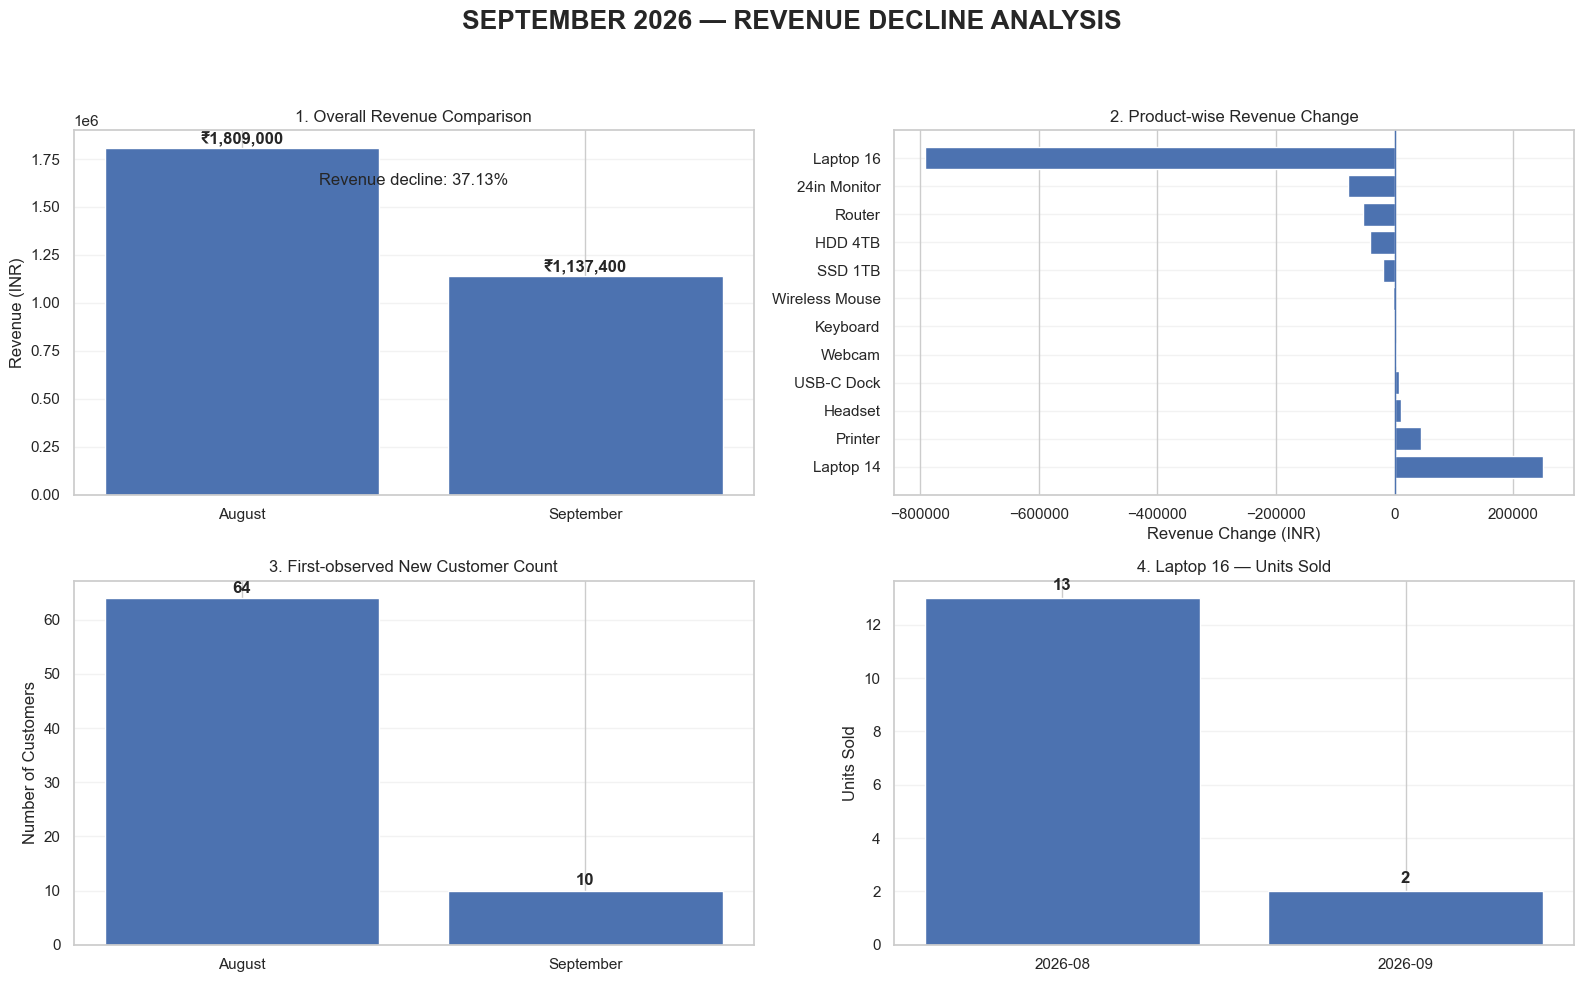

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# Create a 2x2 executive dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

fig.suptitle(
    "SEPTEMBER 2026 — REVENUE DECLINE ANALYSIS",
    fontsize=19,
    fontweight="bold"
)

# --------------------------------------------------
# 1. Overall monthly revenue
# --------------------------------------------------

months = ["August", "September"]
revenue = [1809000, 1137400]

axes[0, 0].bar(months, revenue)

axes[0, 0].set_title("1. Overall Revenue Comparison")
axes[0, 0].set_ylabel("Revenue (INR)")

for i, value in enumerate(revenue):
    axes[0, 0].text(
        i, value + 20000,
        f"₹{value:,.0f}",
        ha="center",
        fontweight="bold"
    )

axes[0, 0].text(
    0.5, 0.85,
    "Revenue decline: 37.13%",
    transform=axes[0, 0].transAxes,
    ha="center",
    fontsize=12
)

# --------------------------------------------------
# 2. Product-level revenue changes
# --------------------------------------------------

product_plot = product_month_comparison.sort_values(
    "revenue_change"
)

axes[0, 1].barh(
    product_plot["product_name"],
    product_plot["revenue_change"]
)

axes[0, 1].set_title("2. Product-wise Revenue Change")
axes[0, 1].set_xlabel("Revenue Change (INR)")
axes[0, 1].axvline(0, linewidth=1)

axes[0, 1].invert_yaxis()

# --------------------------------------------------
# 3. New customer activity
# --------------------------------------------------

new_customers = customer_analysis[
    customer_analysis["customer_type"] == "New"
]

axes[1, 0].bar(
    ["August", "September"],
    new_customers["total_customers"]
)

axes[1, 0].set_title("3. First-observed New Customer Count")
axes[1, 0].set_ylabel("Number of Customers")

for i, value in enumerate(new_customers["total_customers"]):
    axes[1, 0].text(
        i, value + 1,
        str(value),
        ha="center",
        fontweight="bold"
    )

# --------------------------------------------------
# 4. Laptop 16 sales volume
# --------------------------------------------------

axes[1, 1].bar(
    laptop16_analysis["sales_month"],
    laptop16_analysis["units_sold"]
)

axes[1, 1].set_title("4. Laptop 16 — Units Sold")
axes[1, 1].set_ylabel("Units Sold")

for i, value in enumerate(laptop16_analysis["units_sold"]):
    axes[1, 1].text(
        i, value + 0.3,
        str(value),
        ha="center",
        fontweight="bold"
    )

# --------------------------------------------------
# Final formatting
# --------------------------------------------------

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 0.94])

plt.savefig(
    "revenue_decline_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()